# Task C: Trajectory-Level Multi-Horizon Survival Pipeline

This notebook now trains trajectory-level survival predictors for perturbation ensembles.
Each nominal initial condition contributes 8 perturbed trajectories, the input tensor is `(B, 8, T_IN, D)`, and the target tensor is `(B, 8, K)` for the future horizons in `FUTURE_TIMES`.

The model predicts hard-monotone trajectory survival logits by parameterizing logits as an initial value minus cumulative non-negative drops. Ensemble-level survival fraction/count metrics are derived by aggregation:
`Q_hat = mean_i sigmoid(logits_i)` and `N_hat = sum_i sigmoid(logits_i)`.

The old ensemble-level flat curve model is kept behind `RUN_LEGACY_ENSEMBLE_MODEL` for comparison only.


In [1]:
import copy
import os
import random
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, Dataset

SEED = 42
GROUP_SIZE = 8
SURVIVAL_TRIALS = GROUP_SIZE
LOCAL_SMOKE_TEST = False
REQUESTED_NUM_RESULT_BATCHES = 50  # Uses up to 50 shards when available; local runs automatically use the files present.
RAW_T_IN = 200  # Use the first 200 HDF5 snapshots as the observed prefix.
TIME_STRIDE = 1  # Keep every snapshot in that prefix; do not confuse this with time_unbound units.
T_IN = len(range(0, RAW_T_IN, TIME_STRIDE))
# Survival target checkpoints in completed_systems_sampling_1.txt time_unbound units, not HDF5 array indices.
# dataset_v2 has 2001 snapshots, while time_unbound ranges up to 10000.
# The first 200 snapshots end at about time_unbound=1000, so train only on later horizons.
# Sparse horizons reduce redundant step-function labels and make hard-monotone training less brittle.
FUTURE_TIMES = np.array([1100, 1500, 2000, 3000, 4000, 5000, 7000, 8500, 10000], dtype=np.float32)
NUM_FEATURES = 15
SMOKE_MAX_CASES = 1000
MAX_CASES = SMOKE_MAX_CASES if LOCAL_SMOKE_TEST else None

BATCH_SIZE = 128
HIDDEN_DIM = 96
ENCODER_TYPE = "gru"  # Legacy flat case model: one of "gru", "cnn", "tcn".
TRAJECTORY_ENCODER_TYPE = "cnn"  # New trajectory-level model shares one temporal encoder across all 8 trajectories.
GROUP_REDUCE = "mean"  # Legacy flat case input: "mean" or "first".
DROPOUT = 0.20
EPOCHS = 3 if LOCAL_SMOKE_TEST else 80
LR = 1e-3
WEIGHT_DECAY = 2e-4
GRAD_CLIP_NORM = 1.0
TEST_RATIO = 0.2
VAL_RATIO = 0.1  # interpreted as a fraction of total cases, not of the remaining train pool
EARLY_STOPPING_PATIENCE = 12
EARLY_STOPPING_MIN_DELTA = 1e-4
SCHEDULER_PATIENCE = 4
SCHEDULER_FACTOR = 0.5
TEACHER_FORCING_RATIO = 0.0
LAMBDA_MONO = 0.1
USE_POS_WEIGHT = True
POS_WEIGHT_MIN = 0.25
POS_WEIGHT_MAX = 4.0
RUN_LEGACY_ENSEMBLE_MODEL = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATASET_DIR = Path("./dataset_v2")
SAMPLING_ID = 1
REQUESTED_BATCH_IDS = list(range(REQUESTED_NUM_RESULT_BATCHES))
RESULT_PATHS = [
    DATASET_DIR / f"results_batch_{batch_id:02d}_sampling_{SAMPLING_ID}.hdf5"
    for batch_id in REQUESTED_BATCH_IDS
    if (DATASET_DIR / f"results_batch_{batch_id:02d}_sampling_{SAMPLING_ID}.hdf5").exists()
]
LABELS_PATH = DATASET_DIR / f"completed_systems_sampling_{SAMPLING_ID}.txt"

AVAILABLE_BATCH_IDS = [int(path.name.split("_batch_")[1].split("_")[0]) for path in RESULT_PATHS]
if not RESULT_PATHS:
    raise FileNotFoundError(f"No result shards found under {DATASET_DIR} for sampling {SAMPLING_ID}")
if len(RESULT_PATHS) < REQUESTED_NUM_RESULT_BATCHES:
    print(f"Found {len(RESULT_PATHS)} / {REQUESTED_NUM_RESULT_BATCHES} requested result shards; using available local subset.")

print("Dataset dir:", DATASET_DIR)
print("Local smoke test:", LOCAL_SMOKE_TEST)
print("Requested result batches:", REQUESTED_BATCH_IDS[:5], "...", REQUESTED_BATCH_IDS[-1])
print("Available result batches:", AVAILABLE_BATCH_IDS)
print("Max cases:", MAX_CASES)
print("Raw/effective input steps:", {"raw": RAW_T_IN, "stride": TIME_STRIDE, "effective": T_IN})
print("Future survival times in time_unbound units:", FUTURE_TIMES.tolist())
print("Trajectory-level monotonicity lambda:", LAMBDA_MONO)


Using device: cuda
Found 5 / 50 requested result shards; using available local subset.
Dataset dir: dataset_v2
Local smoke test: False
Requested result batches: [0, 1, 2, 3, 4] ... 49
Available result batches: [0, 1, 2, 3, 4]
Max cases: None
Raw/effective input steps: {'raw': 200, 'stride': 1, 'effective': 200}
Future survival times in time_unbound units: [1100.0, 1500.0, 2000.0, 3000.0, 4000.0, 5000.0, 7000.0, 8500.0, 10000.0]
Trajectory-level monotonicity lambda: 0.1


In [2]:
RESULT_KEYS = [
    "aratios_complete",
    "mratios_complete",
    "eccs_complete",
    "incs_complete",
    "APs_complete",
    "LANs_complete",
]


def load_one_h5(path, keys, T=None, stride=1, max_rows=None, dtype=np.float32):
    time_sl = slice(None, None, stride) if T is None else slice(0, T, stride)
    row_sl = slice(None) if max_rows is None else slice(0, max_rows)
    out = {}
    with h5py.File(path, "r") as f:
        for key in keys:
            out[key] = f[key][row_sl, time_sl, ...].astype(dtype)
    return out


def load_all_batches(paths, keys, T=None, stride=1, max_rows=None, dtype=np.float32):
    shards = []
    remaining = None if max_rows is None else int(max_rows)
    for path in paths:
        if not path.exists():
            raise FileNotFoundError(path)
        if remaining is not None and remaining <= 0:
            break
        shard = load_one_h5(path, keys=keys, T=T, stride=stride, max_rows=remaining, dtype=dtype)
        shards.append(shard)
        if remaining is not None:
            remaining -= shard[keys[0]].shape[0]

    if not shards:
        raise ValueError("No HDF5 shards were loaded")

    return {key: np.concatenate([shard[key] for shard in shards], axis=0) for key in keys}


def sincos(x: np.ndarray) -> np.ndarray:
    x = x.astype(np.float32)
    return np.concatenate([np.sin(x), np.cos(x)], axis=-1)


def build_orbital_feature_stack(data: dict) -> np.ndarray:
    ar = data["aratios_complete"].astype(np.float32)
    mr = data["mratios_complete"].astype(np.float32)
    ec = data["eccs_complete"].astype(np.float32)
    inc = data["incs_complete"].astype(np.float32)
    ap = sincos(data["APs_complete"])
    lan = sincos(data["LANs_complete"])
    X = np.concatenate([ar, mr, ec, inc, ap, lan], axis=-1)
    assert X.shape[-1] == NUM_FEATURES, X.shape
    return X.astype(np.float32)


max_trajectories = None if MAX_CASES is None else MAX_CASES * GROUP_SIZE
data = load_all_batches(
    RESULT_PATHS,
    keys=RESULT_KEYS,
    T=RAW_T_IN,
    stride=TIME_STRIDE,
    max_rows=max_trajectories,
)
X_traj = build_orbital_feature_stack(data)
assert X_traj.shape[1] == T_IN, (X_traj.shape, T_IN)
print("Trajectory feature tensor:", X_traj.shape)


Trajectory feature tensor: (40000, 200, 15)


In [3]:
labels = pd.read_csv(
    LABELS_PATH,
    sep=r"\s+",
    header=None,
    names=["index", "num_batch", "time_unbound", "ignore_other_than_minus1", "diagnosis"],
)

labels = labels.astype(
    {
        "index": "int64",
        "num_batch": "int64",
        "time_unbound": "float32",
        "ignore_other_than_minus1": "float32",
        "diagnosis": "int64",
    }
)

# Match the concatenated result-file order and ignore labels for result shards that are not present locally.
labels = labels[labels["num_batch"].isin(AVAILABLE_BATCH_IDS)].copy()
labels = labels.sort_values(["num_batch", "index"], ascending=True).reset_index(drop=True)
if max_trajectories is not None:
    labels = labels.iloc[:max_trajectories].reset_index(drop=True)
labels["raw_case_id"] = np.arange(len(labels)) // GROUP_SIZE

assert len(labels) == len(X_traj), (len(labels), len(X_traj))

valid_label_mask = (labels["time_unbound"] >= 0) & (labels["diagnosis"] == 0)
invalid_label_count = int((~valid_label_mask).sum())
if invalid_label_count:
    print(
        f"Dropping {invalid_label_count} trajectories with invalid survival labels "
        "(time_unbound < 0 or diagnosis != 0)."
    )
    X_traj = X_traj[valid_label_mask.to_numpy()]
    labels = labels.loc[valid_label_mask].reset_index(drop=True)

# Keep finite trajectory prefixes only.
finite_mask = np.isfinite(X_traj).all(axis=(1, 2))
X_traj = X_traj[finite_mask]
labels = labels.loc[finite_mask].reset_index(drop=True)

# Cleaning can break a perturbation set, so keep complete 8-sample cases only.
case_counts = labels["raw_case_id"].value_counts().sort_index()
complete_case_ids = case_counts[case_counts == GROUP_SIZE].index.to_numpy()
complete_mask = labels["raw_case_id"].isin(complete_case_ids).to_numpy()

X_traj = X_traj[complete_mask]
labels = labels.loc[complete_mask].reset_index(drop=True)
labels["case_id"], _ = pd.factorize(labels["raw_case_id"], sort=True)


def build_case_inputs(X: np.ndarray, case_ids: np.ndarray, reduce: str = "mean") -> np.ndarray:
    xs = []
    for case_id in np.unique(case_ids):
        group = X[case_ids == case_id]
        if reduce == "mean":
            xs.append(group.mean(axis=0))
        elif reduce == "first":
            xs.append(group[0])
        else:
            raise ValueError(f"Unsupported reduce mode: {reduce}")
    return np.stack(xs).astype(np.float32)


def build_case_set_inputs(X: np.ndarray, case_ids: np.ndarray, group_size: int = GROUP_SIZE) -> np.ndarray:
    xs = []
    for case_id in np.unique(case_ids):
        group = X[case_ids == case_id]
        if len(group) != group_size:
            raise ValueError(f"Case {case_id} has {len(group)} trajectories, expected {group_size}")
        xs.append(group)
    return np.stack(xs).astype(np.float32)


# CHANGED: trajectory-level multi-horizon target construction.
def build_trajectory_survival_targets(
    time_unbound: np.ndarray,
    case_ids: np.ndarray,
    future_times: np.ndarray,
    group_size: int = GROUP_SIZE,
) -> np.ndarray:
    """Return trajectory-level multi-horizon binary labels with shape (num_cases, 8, K)."""
    ys = []
    for case_id in np.unique(case_ids):
        group_times = time_unbound[case_ids == case_id].astype(np.float32)
        if len(group_times) != group_size:
            raise ValueError(f"Case {case_id} has {len(group_times)} labels, expected {group_size}")
        y_group = (group_times[:, None] >= future_times[None, :]).astype(np.float32)
        ys.append(y_group)
    y = np.stack(ys).astype(np.float32)
    assert y.shape[1] == group_size
    assert np.all(y[:, :, 1:] <= y[:, :, :-1] + 1e-6)
    return y


def build_survival_targets(time_unbound: np.ndarray, case_ids: np.ndarray, future_times: np.ndarray) -> np.ndarray:
    """Legacy ensemble-level survival fraction target Q with shape (num_cases, K)."""
    return build_trajectory_survival_targets(time_unbound, case_ids, future_times).mean(axis=1)


case_ids = labels["case_id"].to_numpy()
time_unbound = labels["time_unbound"].to_numpy()

# Legacy case-level arrays are kept for optional comparison only.
X_case = build_case_inputs(X_traj, case_ids=case_ids, reduce=GROUP_REDUCE)
X_case_set = build_case_set_inputs(X_traj, case_ids=case_ids, group_size=GROUP_SIZE)
y_traj_case = build_trajectory_survival_targets(time_unbound, case_ids=case_ids, future_times=FUTURE_TIMES)
q_case = y_traj_case.mean(axis=1).astype(np.float32)
n_case = y_traj_case.sum(axis=1).astype(np.float32)
y_case = q_case  # Backward-compatible name for legacy ensemble-fraction code.

assert X_case_set.shape[:3] == (len(y_traj_case), GROUP_SIZE, T_IN)
assert np.allclose(q_case, build_survival_targets(time_unbound, case_ids=case_ids, future_times=FUTURE_TIMES))

print("After finite filtering and complete-case filtering:")
print("  trajectories       :", X_traj.shape[0])
print("  cases              :", y_traj_case.shape[0])
print("  set input X        :", X_case_set.shape, "# [B, 8, T_in, D]")
print("  trajectory target Y:", y_traj_case.shape, "# [B, 8, K]")
print("  fraction target Q  :", q_case.shape, "# [B, K]")
print("  count target N     :", n_case.shape, "# [B, K]")
print("  legacy case input  :", X_case.shape)
print("  target tail fraction distribution:", pd.Series(q_case[:, -1]).describe())
print("  target tail count distribution:", pd.Series(n_case[:, -1].astype(int)).describe())


After finite filtering and complete-case filtering:
  trajectories       : 40000
  cases              : 5000
  set input X        : (5000, 8, 200, 15) # [B, 8, T_in, D]
  trajectory target Y: (5000, 8, 9) # [B, 8, K]
  fraction target Q  : (5000, 9) # [B, K]
  count target N     : (5000, 9) # [B, K]
  legacy case input  : (5000, 200, 15)
  target tail fraction distribution: count    5000.000000
mean        0.307650
std         0.402138
min         0.000000
25%         0.000000
50%         0.000000
75%         0.625000
max         1.000000
dtype: float64
  target tail count distribution: count    5000.000000
mean        2.461200
std         3.217105
min         0.000000
25%         0.000000
50%         0.000000
75%         5.000000
max         8.000000
dtype: float64


In [4]:
def _allocate_stratified_counts(bin_sizes: np.ndarray, target_total: int) -> np.ndarray:
    if target_total < 0 or target_total > int(bin_sizes.sum()):
        raise ValueError(f"Invalid target_total={target_total} for bin_sizes={bin_sizes}")

    raw = bin_sizes.astype(np.float64)
    if raw.sum() == 0:
        return np.zeros_like(bin_sizes, dtype=np.int64)

    ideal = raw / raw.sum() * target_total
    base = np.floor(ideal).astype(np.int64)
    remainder = int(target_total - base.sum())

    if remainder > 0:
        order = np.argsort(-(ideal - base))
        for i in order[:remainder]:
            base[i] += 1

    base = np.minimum(base, bin_sizes.astype(np.int64))
    deficit = int(target_total - base.sum())
    if deficit > 0:
        spare_order = np.argsort(-(bin_sizes - base))
        for i in spare_order:
            if deficit == 0:
                break
            spare = int(bin_sizes[i] - base[i])
            if spare <= 0:
                continue
            take = min(spare, deficit)
            base[i] += take
            deficit -= take

    return base.astype(np.int64)


def stratified_case_split(y_curve: np.ndarray, test_ratio=0.2, val_ratio=0.1, seed=42):
    rng = np.random.default_rng(seed)
    n_cases = len(y_curve)
    target_test = int(round(n_cases * test_ratio))
    target_val = int(round(n_cases * val_ratio))
    if target_test + target_val >= n_cases:
        raise ValueError("test_ratio + val_ratio must leave at least one training sample")

    anchor = y_curve[:, -1]
    bins = np.where(anchor == 0.0, 0, np.where(anchor == 1.0, 2, 1))
    unique_bins = np.unique(bins)
    grouped_indices = []
    bin_sizes = []

    for b in unique_bins:
        idx = np.where(bins == b)[0]
        rng.shuffle(idx)
        grouped_indices.append(idx)
        bin_sizes.append(len(idx))

    bin_sizes = np.array(bin_sizes, dtype=np.int64)
    test_counts = _allocate_stratified_counts(bin_sizes, target_test)
    remaining_sizes = bin_sizes - test_counts
    val_counts = _allocate_stratified_counts(remaining_sizes, target_val)

    train_parts, val_parts, test_parts = [], [], []
    for idx, n_test, n_val in zip(grouped_indices, test_counts, val_counts):
        test_idx = idx[:n_test]
        val_idx = idx[n_test:n_test + n_val]
        train_idx = idx[n_test + n_val:]
        train_parts.append(train_idx)
        val_parts.append(val_idx)
        test_parts.append(test_idx)

    train_idx = np.concatenate(train_parts)
    val_idx = np.concatenate(val_parts)
    test_idx = np.concatenate(test_parts)

    rng.shuffle(train_idx)
    rng.shuffle(val_idx)
    rng.shuffle(test_idx)

    assert len(train_idx) + len(val_idx) + len(test_idx) == n_cases
    assert len(val_idx) == target_val, (len(val_idx), target_val)
    assert len(test_idx) == target_test, (len(test_idx), target_test)
    assert len(np.intersect1d(train_idx, val_idx)) == 0
    assert len(np.intersect1d(train_idx, test_idx)) == 0
    assert len(np.intersect1d(val_idx, test_idx)) == 0
    return train_idx, val_idx, test_idx


train_idx, val_idx, test_idx = stratified_case_split(
    q_case,
    test_ratio=TEST_RATIO,
    val_ratio=VAL_RATIO,
    seed=SEED,
)

X_set_train, X_set_val, X_set_test = X_case_set[train_idx], X_case_set[val_idx], X_case_set[test_idx]
y_train, y_val, y_test = y_traj_case[train_idx], y_traj_case[val_idx], y_traj_case[test_idx]
q_train, q_val, q_test = q_case[train_idx], q_case[val_idx], q_case[test_idx]
n_train, n_val, n_test = n_case[train_idx], n_case[val_idx], n_case[test_idx]

# Normalize trajectory-level inputs using only the training split. Shape is [B, 8, T_in, D].
set_mu = X_set_train.mean(axis=(0, 1, 2), keepdims=True)
set_sd = X_set_train.std(axis=(0, 1, 2), keepdims=True) + 1e-6
X_set_train = (X_set_train - set_mu) / set_sd
X_set_val = (X_set_val - set_mu) / set_sd
X_set_test = (X_set_test - set_mu) / set_sd

# Optional legacy ensemble-level flat inputs, normalized independently from the trajectory-level path.
X_train, X_val, X_test = X_case[train_idx], X_case[val_idx], X_case[test_idx]
mu = X_train.mean(axis=(0, 1), keepdims=True)
sd = X_train.std(axis=(0, 1), keepdims=True) + 1e-6
X_train = (X_train - mu) / sd
X_val = (X_val - mu) / sd
X_test = (X_test - mu) / sd

print("Trajectory-level splits:")
print("  Train X/Y/Q/N:", X_set_train.shape, y_train.shape, q_train.shape, n_train.shape)
print("  Val   X/Y/Q/N:", X_set_val.shape, y_val.shape, q_val.shape, n_val.shape)
print("  Test  X/Y/Q/N:", X_set_test.shape, y_test.shape, q_test.shape, n_test.shape)
print("Legacy flat case splits:")
print("  Train X/Q:", X_train.shape, q_train.shape)
print("  Val   X/Q:", X_val.shape, q_val.shape)
print("  Test  X/Q:", X_test.shape, q_test.shape)
print("Split counts (cases):", {"train": len(train_idx), "val": len(val_idx), "test": len(test_idx)})
print("Ratios:", {"train": round(len(train_idx) / len(q_case), 4), "val": round(len(val_idx) / len(q_case), 4), "test": round(len(test_idx) / len(q_case), 4)})


class SurvivalDataset(Dataset):
    """Legacy ensemble-level dataset: X=[B,T,D], Q=[B,K]."""
    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


# CHANGED: trajectory-level dataloader returns X, Y, Q, and N.
class TrajectorySurvivalDataset(Dataset):
    """Trajectory-level dataset: X=[B,8,T,D], Y=[B,8,K], Q/N=[B,K]."""
    def __init__(self, X: np.ndarray, y: np.ndarray, q: np.ndarray | None = None, n: np.ndarray | None = None):
        if y.ndim != 3:
            raise ValueError(f"Expected Y shape [B,8,K], got {y.shape}")
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        q = y.mean(axis=1).astype(np.float32) if q is None else q.astype(np.float32)
        n = y.sum(axis=1).astype(np.float32) if n is None else n.astype(np.float32)
        self.q = torch.tensor(q, dtype=torch.float32)
        self.n = torch.tensor(n, dtype=torch.float32)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx], self.q[idx], self.n[idx]


train_loader = DataLoader(SurvivalDataset(X_train, q_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(SurvivalDataset(X_val, q_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(SurvivalDataset(X_test, q_test), batch_size=BATCH_SIZE, shuffle=False)

traj_train_loader = DataLoader(TrajectorySurvivalDataset(X_set_train, y_train, q_train, n_train), batch_size=BATCH_SIZE, shuffle=True)
traj_val_loader = DataLoader(TrajectorySurvivalDataset(X_set_val, y_val, q_val, n_val), batch_size=BATCH_SIZE, shuffle=False)
traj_test_loader = DataLoader(TrajectorySurvivalDataset(X_set_test, y_test, q_test, n_test), batch_size=BATCH_SIZE, shuffle=False)


Trajectory-level splits:
  Train X/Y/Q/N: (3500, 8, 200, 15) (3500, 8, 9) (3500, 9) (3500, 9)
  Val   X/Y/Q/N: (500, 8, 200, 15) (500, 8, 9) (500, 9) (500, 9)
  Test  X/Y/Q/N: (1000, 8, 200, 15) (1000, 8, 9) (1000, 9) (1000, 9)
Legacy flat case splits:
  Train X/Q: (3500, 200, 15) (3500, 9)
  Val   X/Q: (500, 200, 15) (500, 9)
  Test  X/Q: (1000, 200, 15) (1000, 9)
Split counts (cases): {'train': 3500, 'val': 500, 'test': 1000}
Ratios: {'train': 0.7, 'val': 0.1, 'test': 0.2}


In [5]:
class ConvBlock1D(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, kernel_size: int, dropout: float = 0.1):
        super().__init__()
        padding = kernel_size // 2
        self.net = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel_size=kernel_size, padding=padding),
            nn.BatchNorm1d(out_ch),
            nn.GELU(),
            nn.Dropout(dropout),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class TemporalBlock(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, kernel_size: int = 3, dilation: int = 1, dropout: float = 0.1):
        super().__init__()
        padding = (kernel_size - 1) * dilation // 2
        self.net = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel_size, padding=padding, dilation=dilation),
            nn.BatchNorm1d(out_ch),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Conv1d(out_ch, out_ch, kernel_size, padding=padding, dilation=dilation),
            nn.BatchNorm1d(out_ch),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.skip = nn.Identity() if in_ch == out_ch else nn.Conv1d(in_ch, out_ch, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x) + self.skip(x)


class GRUEncoder(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, dropout: float = 0.0):
        super().__init__()
        self.in_proj = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.gru = nn.GRU(input_size=hidden_dim, hidden_size=hidden_dim, num_layers=1, batch_first=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.in_proj(x)
        _, h_n = self.gru(x)
        return h_n[-1]


class CNNEncoder(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, dropout: float = 0.1):
        super().__init__()
        self.backbone = nn.Sequential(
            ConvBlock1D(input_dim, 64, kernel_size=7, dropout=dropout),
            ConvBlock1D(64, 128, kernel_size=5, dropout=dropout),
            ConvBlock1D(128, hidden_dim, kernel_size=3, dropout=dropout),
            nn.AdaptiveAvgPool1d(1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.transpose(1, 2)
        return self.backbone(x).squeeze(-1)


class TCNEncoder(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, channels=(64, 128, 128), dropout: float = 0.1):
        super().__init__()
        blocks = []
        prev = input_dim
        for i, ch in enumerate(channels):
            blocks.append(TemporalBlock(prev, ch, kernel_size=3, dilation=2 ** i, dropout=dropout))
            prev = ch
        self.tcn = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.proj = nn.Linear(prev, hidden_dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.transpose(1, 2)
        h = self.tcn(x)
        h = self.pool(h).squeeze(-1)
        return self.proj(h)


class Encoder(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, encoder_type: str = "gru", dropout: float = 0.1):
        super().__init__()
        encoder_type = encoder_type.lower()
        if encoder_type == "gru":
            self.encoder = GRUEncoder(input_dim=input_dim, hidden_dim=hidden_dim, dropout=dropout)
        elif encoder_type == "cnn":
            self.encoder = CNNEncoder(input_dim=input_dim, hidden_dim=hidden_dim, dropout=dropout)
        elif encoder_type == "tcn":
            self.encoder = TCNEncoder(input_dim=input_dim, hidden_dim=hidden_dim, dropout=dropout)
        else:
            raise ValueError(f"Unsupported encoder_type: {encoder_type}")

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.encoder(x)


class AutoregressiveDecoder(nn.Module):
    def __init__(self, hidden_dim: int, horizon: int, dropout: float = 0.1):
        super().__init__()
        self.horizon = horizon
        self.step_embed = nn.Embedding(horizon, hidden_dim)
        self.input_proj = nn.Sequential(
            nn.Linear(hidden_dim + 1, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.gru_cell = nn.GRUCell(input_size=hidden_dim, hidden_size=hidden_dim)
        self.hidden_norm = nn.LayerNorm(hidden_dim)
        self.alpha_head = nn.Sequential(
            nn.Linear(2 * hidden_dim + 1, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, context: torch.Tensor, targets: torch.Tensor | None = None, teacher_forcing: bool = False) -> torch.Tensor:
        batch_size = context.size(0)
        hidden = context
        prev_p = torch.ones(batch_size, 1, device=context.device, dtype=context.dtype)
        preds = []

        for step in range(self.horizon):
            step_ids = torch.full((batch_size,), step, device=context.device, dtype=torch.long)
            step_feat = self.step_embed(step_ids)
            decoder_in = self.input_proj(torch.cat([prev_p, step_feat], dim=-1))
            hidden = self.hidden_norm(self.gru_cell(decoder_in, hidden))
            alpha_logits = self.alpha_head(torch.cat([hidden, step_feat, prev_p], dim=-1))
            alpha = torch.sigmoid(alpha_logits)
            p_t = prev_p * alpha
            preds.append(p_t)

            if teacher_forcing and targets is not None:
                prev_p = targets[:, step:step + 1]
            else:
                prev_p = p_t

        return torch.cat(preds, dim=1)


class Seq2SeqSurvivalModel(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, horizon: int, encoder_type: str = "gru", dropout: float = 0.1):
        super().__init__()
        self.encoder = Encoder(input_dim=input_dim, hidden_dim=hidden_dim, encoder_type=encoder_type, dropout=dropout)
        self.decoder = AutoregressiveDecoder(hidden_dim=hidden_dim, horizon=horizon, dropout=dropout)

    def forward(self, x: torch.Tensor, targets: torch.Tensor | None = None, teacher_forcing: bool = False) -> torch.Tensor:
        context = self.encoder(x)
        return self.decoder(context=context, targets=targets, teacher_forcing=teacher_forcing)


In [6]:
class BinomialSurvivalLoss(nn.Module):
    def __init__(
        self,
        n_trials: int = GROUP_SIZE,
        time_decay: float = 0.95,
        eps: float = 1e-6,
        include_combinatorial: bool = True,
    ):
        super().__init__()
        self.n_trials = float(n_trials)
        self.time_decay = time_decay
        self.eps = eps
        self.include_combinatorial = include_combinatorial

    def forward(self, y_pred: torch.Tensor, y_true: torch.Tensor) -> torch.Tensor:
        if y_pred.shape != y_true.shape:
            raise ValueError(f"Shape mismatch: {y_pred.shape} vs {y_true.shape}")

        horizon = y_pred.size(1)
        weights = torch.tensor(
            [self.time_decay ** k for k in range(horizon)],
            device=y_pred.device,
            dtype=y_pred.dtype,
        )
        weights = weights / weights.sum()

        p = y_pred.clamp(self.eps, 1.0 - self.eps)
        n = torch.full_like(y_true, self.n_trials)
        observed_count = torch.round(y_true * self.n_trials).clamp(0.0, self.n_trials)

        log_prob = observed_count * torch.log(p) + (n - observed_count) * torch.log1p(-p)
        if self.include_combinatorial:
            log_prob = log_prob + torch.lgamma(n + 1.0) - torch.lgamma(observed_count + 1.0) - torch.lgamma(n - observed_count + 1.0)

        per_step_nll = -log_prob
        return (per_step_nll * weights.view(1, horizon)).sum(dim=1).mean()


@torch.no_grad()
def evaluate_model(model, loader, criterion):
    model.eval()
    losses = []
    preds_all = []
    targets_all = []

    for xb, yb in loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)
        pred = model(xb)
        loss = criterion(pred, yb)
        losses.append(float(loss.item()))
        preds_all.append(pred.detach().cpu())
        targets_all.append(yb.detach().cpu())

    preds = torch.cat(preds_all, dim=0).numpy()
    targets = torch.cat(targets_all, dim=0).numpy()
    mae_per_horizon = np.mean(np.abs(preds - targets), axis=0)
    mse_per_horizon = np.mean((preds - targets) ** 2, axis=0)
    overall_mae = float(np.mean(np.abs(preds - targets)))
    monotone_fraction = float(np.mean(np.all(preds[:, 1:] <= preds[:, :-1] + 1e-6, axis=1)))

    return {
        "loss": float(np.mean(losses)),
        "overall_mae": overall_mae,
        "mae_per_horizon": mae_per_horizon,
        "mse_per_horizon": mse_per_horizon,
        "monotone_fraction": monotone_fraction,
        "preds": preds,
        "targets": targets,
    }


def evaluate_mean_curve_baseline(y_ref: np.ndarray, y_eval: np.ndarray, criterion: nn.Module):
    mean_curve = y_ref.mean(axis=0, keepdims=True).astype(np.float32)
    preds = np.repeat(mean_curve, repeats=len(y_eval), axis=0)
    preds_t = torch.tensor(preds, dtype=torch.float32)
    targets_t = torch.tensor(y_eval, dtype=torch.float32)
    loss = float(criterion(preds_t, targets_t).item())
    mae_per_horizon = np.mean(np.abs(preds - y_eval), axis=0)
    mse_per_horizon = np.mean((preds - y_eval) ** 2, axis=0)
    overall_mae = float(np.mean(np.abs(preds - y_eval)))
    monotone_fraction = float(np.mean(np.all(preds[:, 1:] <= preds[:, :-1] + 1e-6, axis=1)))
    return {
        "loss": loss,
        "overall_mae": overall_mae,
        "mae_per_horizon": mae_per_horizon,
        "mse_per_horizon": mse_per_horizon,
        "monotone_fraction": monotone_fraction,
        "preds": preds,
        "targets": y_eval,
        "mean_curve": mean_curve.squeeze(0),
    }


def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    epochs=80,
    lr=1e-3,
    weight_decay=1e-4,
    grad_clip_norm=1.0,
    teacher_forcing_ratio=0.0,
    scheduler_patience=4,
    scheduler_factor=0.5,
    early_stopping_patience=12,
    early_stopping_min_delta=1e-4,
):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=scheduler_factor, patience=scheduler_patience)

    history = {"train_loss": [], "val_loss": [], "lr": []}
    best_state = None
    best_val = float("inf")
    best_epoch = 0
    patience_counter = 0

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        total_n = 0

        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)
            use_tf = teacher_forcing_ratio > 0.0 and random.random() < teacher_forcing_ratio
            pred = model(xb, targets=yb if use_tf else None, teacher_forcing=use_tf)
            loss = criterion(pred, yb)
            loss.backward()
            if grad_clip_norm is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)
            optimizer.step()

            bs = xb.size(0)
            total_loss += float(loss.item()) * bs
            total_n += bs

        train_loss = total_loss / max(total_n, 1)
        val_metrics = evaluate_model(model, val_loader, criterion)
        val_loss = val_metrics["loss"]
        scheduler.step(val_loss)

        current_lr = optimizer.param_groups[0]["lr"]
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["lr"].append(current_lr)

        improved = val_loss < (best_val - early_stopping_min_delta)
        if improved:
            best_val = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        print(
            f"epoch {epoch:03d} | train_loss {train_loss:.6f} | val_loss {val_loss:.6f} | "
            f"val_mae {val_metrics['overall_mae']:.6f} | lr {current_lr:.2e} | patience {patience_counter}/{early_stopping_patience}"
        )

        if patience_counter >= early_stopping_patience:
            print(f"Early stopping at epoch {epoch:03d}; best epoch was {best_epoch:03d} with val_loss {best_val:.6f}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history, {"best_epoch": best_epoch, "best_val": best_val}


# CHANGED: trajectory-level BCEWithLogits loss, hard-monotone diagnostics, metrics, and train loop.
class TrajectorySurvivalLoss(nn.Module):
    """Trajectory-level BCEWithLogits loss plus a residual monotonicity diagnostic penalty.

    The model head below is hard-monotone, so mono_loss should be near zero. Keeping this
    term in the objective is a cheap guard if a non-monotone head is swapped in later.
    """
    def __init__(self, lambda_mono: float = 0.1, pos_weight: torch.Tensor | None = None):
        super().__init__()
        self.lambda_mono = float(lambda_mono)
        if pos_weight is not None:
            self.register_buffer("pos_weight", pos_weight.detach().clone().float())
        else:
            self.pos_weight = None

    def components(self, logits: torch.Tensor, targets: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        if logits.shape != targets.shape:
            raise ValueError(f"Shape mismatch: logits {logits.shape} vs targets {targets.shape}")
        pos_weight = None if self.pos_weight is None else self.pos_weight.to(device=logits.device, dtype=logits.dtype)
        traj_bce = F.binary_cross_entropy_with_logits(logits, targets, pos_weight=pos_weight)
        probs = torch.sigmoid(logits)
        mono = F.relu(probs[..., 1:] - probs[..., :-1]).mean() if probs.size(-1) > 1 else probs.new_tensor(0.0)
        total = traj_bce + self.lambda_mono * mono
        return total, traj_bce, mono

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        total, _, _ = self.components(logits, targets)
        return total


def _trajectory_metrics_from_probs(
    probs: np.ndarray,
    targets: np.ndarray,
    total_loss: float | None = None,
    trajectory_bce: float | None = None,
    mono_loss: float | None = None,
) -> dict:
    q_hat = probs.mean(axis=1)
    q_true = targets.mean(axis=1)
    n_hat = probs.sum(axis=1)
    n_true = targets.sum(axis=1)
    traj_acc_per_horizon = ((probs >= 0.5) == (targets >= 0.5)).mean(axis=(0, 1))
    mae_per_horizon = np.mean(np.abs(q_hat - q_true), axis=0)
    mse_per_horizon = np.mean((q_hat - q_true) ** 2, axis=0)
    count_mae_per_horizon = np.mean(np.abs(n_hat - n_true), axis=0)
    monotone_fraction = float(np.mean(np.all(probs[:, :, 1:] <= probs[:, :, :-1] + 1e-6, axis=2))) if probs.shape[-1] > 1 else 1.0
    return {
        "loss": float(total_loss) if total_loss is not None else float("nan"),
        "trajectory_bce": float(trajectory_bce) if trajectory_bce is not None else float("nan"),
        "mono_loss": float(mono_loss) if mono_loss is not None else float("nan"),
        "traj_acc_per_horizon": traj_acc_per_horizon,
        "ensemble_fraction_mae": float(np.mean(np.abs(q_hat - q_true))),
        "ensemble_fraction_mse": float(np.mean((q_hat - q_true) ** 2)),
        "count_mae": float(np.mean(np.abs(n_hat - n_true))),
        "mae_per_horizon": mae_per_horizon,
        "mse_per_horizon": mse_per_horizon,
        "count_mae_per_horizon": count_mae_per_horizon,
        "overall_mae": float(np.mean(np.abs(q_hat - q_true))),
        "monotone_fraction": monotone_fraction,
        "preds": q_hat,
        "targets": q_true,
        "counts_pred": n_hat,
        "counts_true": n_true,
        "traj_probs": probs,
        "traj_targets": targets,
    }


@torch.no_grad()
def evaluate_trajectory_model(model, loader, criterion: TrajectorySurvivalLoss):
    model.eval()
    total_loss_sum = 0.0
    bce_sum = 0.0
    mono_sum = 0.0
    total_n = 0
    probs_all = []
    targets_all = []

    for xb, yb, qb, nb in loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)
        logits = model(xb)
        total_loss, traj_bce, mono_loss = criterion.components(logits, yb)

        bs = xb.size(0)
        total_loss_sum += float(total_loss.item()) * bs
        bce_sum += float(traj_bce.item()) * bs
        mono_sum += float(mono_loss.item()) * bs
        total_n += bs
        probs_all.append(torch.sigmoid(logits).detach().cpu())
        targets_all.append(yb.detach().cpu())

    probs = torch.cat(probs_all, dim=0).numpy()
    targets = torch.cat(targets_all, dim=0).numpy()
    return _trajectory_metrics_from_probs(
        probs,
        targets,
        total_loss=total_loss_sum / max(total_n, 1),
        trajectory_bce=bce_sum / max(total_n, 1),
        mono_loss=mono_sum / max(total_n, 1),
    )


def evaluate_mean_trajectory_baseline(y_ref: np.ndarray, y_eval: np.ndarray, criterion: TrajectorySurvivalLoss):
    mean_curve = y_ref.mean(axis=(0, 1), keepdims=True).astype(np.float32)  # [1, 1, K]
    probs = np.repeat(mean_curve, repeats=len(y_eval), axis=0)
    probs = np.repeat(probs, repeats=y_eval.shape[1], axis=1).astype(np.float32)
    eps = 1e-6
    logits = torch.logit(torch.tensor(probs).clamp(eps, 1.0 - eps))
    targets_t = torch.tensor(y_eval, dtype=torch.float32)
    total_loss, traj_bce, mono_loss = criterion.components(logits, targets_t)
    metrics = _trajectory_metrics_from_probs(
        probs,
        y_eval.astype(np.float32),
        total_loss=float(total_loss.item()),
        trajectory_bce=float(traj_bce.item()),
        mono_loss=float(mono_loss.item()),
    )
    metrics["mean_curve"] = mean_curve.squeeze((0, 1))
    return metrics


def train_trajectory_model(
    model,
    train_loader,
    val_loader,
    criterion: TrajectorySurvivalLoss,
    epochs=80,
    lr=1e-3,
    weight_decay=1e-4,
    grad_clip_norm=1.0,
    scheduler_patience=4,
    scheduler_factor=0.5,
    early_stopping_patience=12,
    early_stopping_min_delta=1e-4,
):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=scheduler_factor, patience=scheduler_patience)

    history = {"train_loss": [], "train_bce": [], "train_mono": [], "val_loss": [], "val_bce": [], "lr": []}
    best_state = None
    best_val = float("inf")
    best_epoch = 0
    patience_counter = 0

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss_sum = 0.0
        bce_sum = 0.0
        mono_sum = 0.0
        total_n = 0

        for xb, yb, qb, nb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss, traj_bce, mono_loss = criterion.components(logits, yb)
            loss.backward()
            if grad_clip_norm is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)
            optimizer.step()

            bs = xb.size(0)
            total_loss_sum += float(loss.item()) * bs
            bce_sum += float(traj_bce.item()) * bs
            mono_sum += float(mono_loss.item()) * bs
            total_n += bs

        train_loss = total_loss_sum / max(total_n, 1)
        train_bce = bce_sum / max(total_n, 1)
        train_mono = mono_sum / max(total_n, 1)
        val_metrics = evaluate_trajectory_model(model, val_loader, criterion)
        val_loss = val_metrics["loss"]
        scheduler.step(val_loss)

        current_lr = optimizer.param_groups[0]["lr"]
        history["train_loss"].append(train_loss)
        history["train_bce"].append(train_bce)
        history["train_mono"].append(train_mono)
        history["val_loss"].append(val_loss)
        history["val_bce"].append(val_metrics["trajectory_bce"])
        history["lr"].append(current_lr)

        improved = val_loss < (best_val - early_stopping_min_delta)
        if improved:
            best_val = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        print(
            f"epoch {epoch:03d} | train_loss {train_loss:.6f} | train_bce {train_bce:.6f} | "
            f"train_mono {train_mono:.6f} | val_loss {val_loss:.6f} | "
            f"val_bce {val_metrics['trajectory_bce']:.6f} | val_frac_mae {val_metrics['ensemble_fraction_mae']:.6f} | "
            f"lr {current_lr:.2e} | patience {patience_counter}/{early_stopping_patience}"
        )

        if patience_counter >= early_stopping_patience:
            print(f"Early stopping at epoch {epoch:03d}; best epoch was {best_epoch:03d} with val_loss {best_val:.6f}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history, {"best_epoch": best_epoch, "best_val": best_val}


def print_metrics(name: str, metrics: dict):
    print(f"{name} loss             : {metrics['loss']:.6f}")
    print(f"{name} overall_mae      : {metrics['overall_mae']:.6f}")
    print(f"{name} mae_per_horizon  : {np.round(metrics['mae_per_horizon'], 6)}")
    print(f"{name} mse_per_horizon  : {np.round(metrics['mse_per_horizon'], 6)}")
    print(f"{name} monotone_fraction: {metrics['monotone_fraction']:.4f}")


def print_trajectory_metrics(name: str, metrics: dict):
    print(f"{name} total_loss            : {metrics['loss']:.6f}")
    print(f"{name} trajectory_bce        : {metrics['trajectory_bce']:.6f}")
    print(f"{name} mono_loss             : {metrics['mono_loss']:.6f}")
    print(f"{name} traj_acc_per_horizon  : {np.round(metrics['traj_acc_per_horizon'], 4)}")
    print(f"{name} ensemble_fraction_mae : {metrics['ensemble_fraction_mae']:.6f}")
    print(f"{name} ensemble_fraction_mse : {metrics['ensemble_fraction_mse']:.6f}")
    print(f"{name} count_mae             : {metrics['count_mae']:.6f}")
    print(f"{name} count_mae_per_horizon : {np.round(metrics['count_mae_per_horizon'], 4)}")
    print(f"{name} monotone_fraction     : {metrics['monotone_fraction']:.4f}")


In [7]:
def compute_horizon_pos_weight(y: np.ndarray, min_value: float = 0.25, max_value: float = 4.0) -> torch.Tensor:
    """Return BCE positive-class weights per horizon, shaped for logits [B, 8, K]."""
    positives = y.sum(axis=(0, 1)).astype(np.float32)
    total = float(y.shape[0] * y.shape[1])
    negatives = total - positives
    pos_weight = negatives / np.maximum(positives, 1.0)
    pos_weight = np.clip(pos_weight, min_value, max_value).astype(np.float32)
    return torch.tensor(pos_weight.reshape(1, 1, -1), dtype=torch.float32)


trajectory_pos_weight = compute_horizon_pos_weight(y_train, POS_WEIGHT_MIN, POS_WEIGHT_MAX) if USE_POS_WEIGHT else None
if trajectory_pos_weight is not None:
    print("Trajectory BCE pos_weight per horizon:", np.round(trajectory_pos_weight.squeeze().numpy(), 3))

trajectory_criterion = TrajectorySurvivalLoss(lambda_mono=LAMBDA_MONO, pos_weight=trajectory_pos_weight)

baseline_val_metrics = evaluate_mean_trajectory_baseline(y_train, y_val, trajectory_criterion)
baseline_test_metrics = evaluate_mean_trajectory_baseline(y_train, y_test, trajectory_criterion)

print("Mean trajectory-survival baseline:")
print_trajectory_metrics("BASELINE VAL", baseline_val_metrics)
print()
print_trajectory_metrics("BASELINE TEST", baseline_test_metrics)
print()

# The old ensemble-level flat model is kept behind a flag for comparison only.
criterion = BinomialSurvivalLoss(n_trials=SURVIVAL_TRIALS, time_decay=1.0, include_combinatorial=True)
model = None
history = {"train_loss": [], "val_loss": [], "lr": []}
fit_info = {"best_epoch": 0, "best_val": float("nan")}
test_metrics = None
val_metrics = None

if RUN_LEGACY_ENSEMBLE_MODEL:
    model = Seq2SeqSurvivalModel(
        input_dim=NUM_FEATURES,
        hidden_dim=HIDDEN_DIM,
        horizon=len(FUTURE_TIMES),
        encoder_type=ENCODER_TYPE,
        dropout=DROPOUT,
    ).to(DEVICE)

    model, history, fit_info = train_model(
        model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion,
        epochs=EPOCHS,
        lr=LR,
        weight_decay=WEIGHT_DECAY,
        grad_clip_norm=GRAD_CLIP_NORM,
        teacher_forcing_ratio=TEACHER_FORCING_RATIO,
        scheduler_patience=SCHEDULER_PATIENCE,
        scheduler_factor=SCHEDULER_FACTOR,
        early_stopping_patience=EARLY_STOPPING_PATIENCE,
        early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
    )
    print("Legacy flat ensemble-level fit info:", fit_info)
else:
    print("Skipping legacy ensemble-level flat model; set RUN_LEGACY_ENSEMBLE_MODEL=True to run it.")


Trajectory BCE pos_weight per horizon: [1.031 1.166 1.297 1.492 1.654 1.785 1.998 2.138 2.248]
Mean trajectory-survival baseline:
BASELINE VAL total_loss            : 0.900905
BASELINE VAL trajectory_bce        : 0.900905
BASELINE VAL mono_loss             : 0.000000
BASELINE VAL traj_acc_per_horizon  : [0.4955 0.525  0.5512 0.5878 0.615  0.6352 0.663  0.6788 0.691 ]
BASELINE VAL ensemble_fraction_mae : 0.379815
BASELINE VAL ensemble_fraction_mse : 0.173847
BASELINE VAL count_mae             : 3.038519
BASELINE VAL count_mae_per_horizon : [3.1782 3.177  3.1403 3.1263 3.0713 3.0351 2.9364 2.8772 2.8049]
BASELINE VAL monotone_fraction     : 1.0000

BASELINE TEST total_loss            : 0.893384
BASELINE TEST trajectory_bce        : 0.893384
BASELINE TEST mono_loss             : 0.000000
BASELINE TEST traj_acc_per_horizon  : [0.5059 0.5327 0.5602 0.599  0.6266 0.6425 0.6692 0.6834 0.694 ]
BASELINE TEST ensemble_fraction_mae : 0.380134
BASELINE TEST ensemble_fraction_mse : 0.173931
BASELIN

In [8]:
if RUN_LEGACY_ENSEMBLE_MODEL and model is not None:
    val_metrics = evaluate_model(model, val_loader, criterion)
    test_metrics = evaluate_model(model, test_loader, criterion)

    print_metrics("LEGACY MODEL VAL", val_metrics)
    print()
    print_metrics("LEGACY MODEL TEST", test_metrics)
    print()
    print("Improvement over mean trajectory baseline on TEST ensemble_fraction_mae:", baseline_test_metrics["overall_mae"] - test_metrics["overall_mae"])

    fig, axes = plt.subplots(1, 3, figsize=(11, 4))

    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"], label="val")
    axes[0].set_title("Legacy Loss History")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(history["lr"], color="tab:green")
    axes[1].set_title("Legacy Learning Rate")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("LR")

    example_ids = np.arange(min(5, len(test_metrics["preds"])))
    for idx in example_ids:
        axes[2].plot(FUTURE_TIMES, test_metrics["targets"][idx], marker="o", alpha=0.7, color="tab:blue")
        axes[2].plot(FUTURE_TIMES, baseline_test_metrics["preds"][idx], marker="s", alpha=0.35, color="tab:gray")
        axes[2].plot(FUTURE_TIMES, test_metrics["preds"][idx], marker="x", alpha=0.7, color="tab:orange")
    axes[2].set_title("Legacy Target vs Baseline vs Model")
    axes[2].set_xlabel("Future time")
    axes[2].set_ylabel("Survival fraction")
    axes[2].set_ylim(-0.05, 1.05)

    plt.tight_layout()
    plt.show()
else:
    print("Legacy ensemble-level flat model was not run.")

print("Mean training survival fraction:", np.round(q_train.mean(axis=0), 4))
print("Mean testing  survival fraction:", np.round(q_test.mean(axis=0), 4))


Legacy ensemble-level flat model was not run.
Mean training survival fraction: [0.4922 0.4618 0.4354 0.4012 0.3769 0.3591 0.3335 0.3187 0.3079]
Mean testing  survival fraction: [0.4941 0.4672 0.4398 0.401  0.3734 0.3575 0.3308 0.3166 0.306 ]


## Shared Trajectory Encoder + Ensemble Context

This section keeps the 8 perturbation trajectories explicitly and predicts trajectory-level multi-horizon survival logits.

Pipeline:

1. Input: `(B, 8, T_IN, 15)`
2. Shared trajectory encoder: reshape to `(B*8, T_IN, 15)` and encode each trajectory independently
3. Ensemble context: mean-pool the 8 trajectory embeddings
4. Per-trajectory head: concatenate `[h_traj, h_ens]` and output logits `(B, 8, K)`


In [9]:
# Trajectory-level data loaders were built above as traj_train_loader/traj_val_loader/traj_test_loader.
# They return (X, Y, Q, N) with shapes:
#   X: [B, 8, T_in, D]
#   Y: [B, 8, K]
#   Q: [B, K]
#   N: [B, K]
xb, yb, qb, nb = next(iter(traj_train_loader))
print("Trajectory-level batch shapes:")
print("  X:", tuple(xb.shape))
print("  Y:", tuple(yb.shape))
print("  Q:", tuple(qb.shape))
print("  N:", tuple(nb.shape))
assert xb.ndim == 4 and xb.shape[1:] == (GROUP_SIZE, T_IN, NUM_FEATURES)
assert yb.ndim == 3 and yb.shape[1] == GROUP_SIZE and yb.shape[2] == len(FUTURE_TIMES)
assert torch.allclose(qb, yb.mean(dim=1))
assert torch.allclose(nb, yb.sum(dim=1))


Trajectory-level batch shapes:
  X: (128, 8, 200, 15)
  Y: (128, 8, 9)
  Q: (128, 9)
  N: (128, 9)


In [10]:
TRAJ_HIDDEN_DIM = 128
TRAJ_DROPOUT = 0.20
TRAJ_EPOCHS = 3 if LOCAL_SMOKE_TEST else 80


class MonotoneSurvivalHead(nn.Module):
    """Predict non-increasing survival probabilities and return equivalent logits.

    The head predicts an initial logit z0 and non-negative logit drops delta_k.
    z_k = z0 - cumsum(delta_k), so sigmoid(z_k) is guaranteed non-increasing.
    """
    def __init__(
        self,
        input_dim: int,
        hidden_dim: int,
        horizon: int,
        dropout: float = 0.1,
        min_delta: float = 1e-4,
        delta_bias_init: float = -4.0,
    ):
        super().__init__()
        self.horizon = int(horizon)
        self.min_delta = float(min_delta)
        self.delta_bias_init = float(delta_bias_init)
        self.raw_head = nn.Sequential(
            nn.LayerNorm(input_dim),
            nn.Linear(input_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, horizon),
        )
        if horizon > 1:
            nn.init.constant_(self.raw_head[-1].bias[1:], self.delta_bias_init)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        raw = self.raw_head(x)
        if self.horizon == 1:
            return raw

        z0 = raw[..., :1]
        drops = F.softplus(raw[..., 1:]) + self.min_delta
        later_logits = z0 - torch.cumsum(drops, dim=-1)
        return torch.cat([z0, later_logits], dim=-1)


# CHANGED: shared trajectory encoder + ensemble context hard-monotone logits model.
class TrajectoryContextSurvivalModel(nn.Module):
    """Shared trajectory encoder with mean-pooled ensemble context and hard-monotone logits."""
    def __init__(
        self,
        input_dim: int,
        hidden_dim: int,
        horizon: int,
        encoder_type: str = "cnn",
        dropout: float = 0.1,
    ):
        super().__init__()
        self.horizon = horizon
        self.traj_encoder = Encoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            encoder_type=encoder_type,
            dropout=dropout,
        )
        self.head = MonotoneSurvivalHead(
            input_dim=2 * hidden_dim,
            hidden_dim=hidden_dim,
            horizon=horizon,
            dropout=dropout,
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [B, 8, T_in, D]. The same encoder processes each trajectory independently.
        batch_size, group_size, seq_len, feat_dim = x.shape
        x_flat = x.reshape(batch_size * group_size, seq_len, feat_dim)
        h_traj = self.traj_encoder(x_flat).reshape(batch_size, group_size, -1)  # [B, 8, H]
        h_ens = h_traj.mean(dim=1, keepdim=True).expand(-1, group_size, -1)    # [B, 8, H]
        h_cat = torch.cat([h_traj, h_ens], dim=-1)                             # [B, 8, 2H]
        return self.head(h_cat)                                                # [B, 8, K] logits


@torch.no_grad()
def inspect_trajectory_embeddings(model: nn.Module, x: torch.Tensor):
    model.eval()
    batch_size, group_size, seq_len, feat_dim = x.shape
    h = model.traj_encoder(x.reshape(batch_size * group_size, seq_len, feat_dim))
    return h.reshape(batch_size, group_size, -1).detach().cpu().numpy()


epoch 001 | train_loss 0.602840 | train_bce 0.602840 | train_mono 0.000000 | val_loss 0.505926 | val_bce 0.505926 | val_frac_mae 0.225620 | lr 1.00e-03 | patience 0/12
epoch 002 | train_loss 0.448296 | train_bce 0.448296 | train_mono 0.000000 | val_loss 0.431153 | val_bce 0.431153 | val_frac_mae 0.163870 | lr 1.00e-03 | patience 0/12
epoch 003 | train_loss 0.405463 | train_bce 0.405463 | train_mono 0.000000 | val_loss 0.383306 | val_bce 0.383306 | val_frac_mae 0.143248 | lr 1.00e-03 | patience 0/12
epoch 004 | train_loss 0.383044 | train_bce 0.383044 | train_mono 0.000000 | val_loss 0.378563 | val_bce 0.378563 | val_frac_mae 0.135882 | lr 1.00e-03 | patience 0/12
epoch 005 | train_loss 0.363030 | train_bce 0.363030 | train_mono 0.000000 | val_loss 0.369278 | val_bce 0.369278 | val_frac_mae 0.134871 | lr 1.00e-03 | patience 0/12
epoch 006 | train_loss 0.346604 | train_bce 0.346604 | train_mono 0.000000 | val_loss 0.359111 | val_bce 0.359111 | val_frac_mae 0.131500 | lr 1.00e-03 | patien

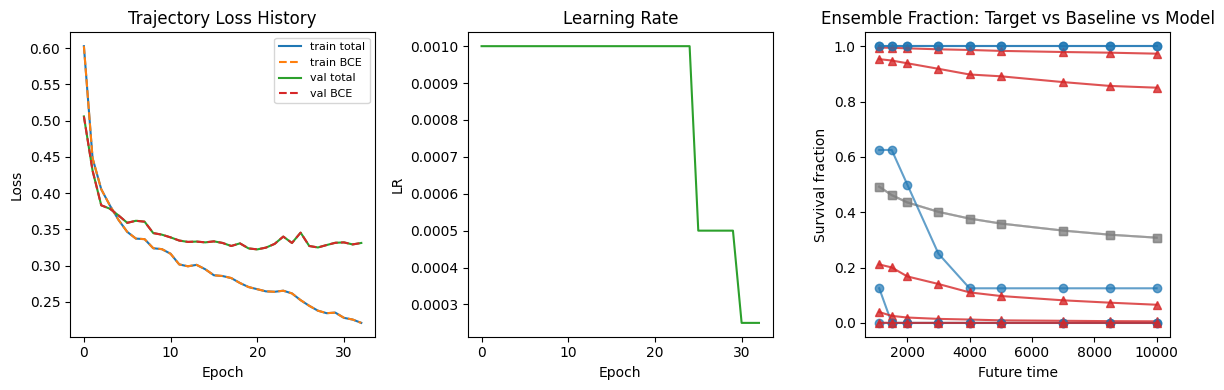

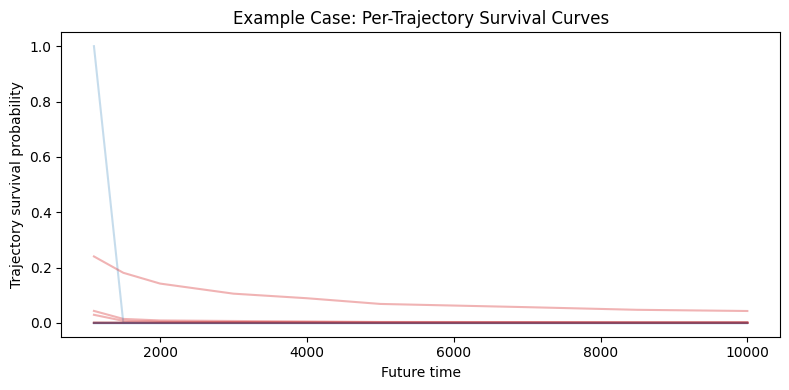

Example trajectory embedding shape: (1, 8, 128)


In [11]:
traj_model = TrajectoryContextSurvivalModel(
    input_dim=NUM_FEATURES,
    hidden_dim=TRAJ_HIDDEN_DIM,
    horizon=len(FUTURE_TIMES),
    encoder_type=TRAJECTORY_ENCODER_TYPE,
    dropout=TRAJ_DROPOUT,
).to(DEVICE)

traj_model, traj_history, traj_fit_info = train_trajectory_model(
    traj_model,
    train_loader=traj_train_loader,
    val_loader=traj_val_loader,
    criterion=trajectory_criterion,
    epochs=TRAJ_EPOCHS,
    lr=LR,
    weight_decay=WEIGHT_DECAY,
    grad_clip_norm=GRAD_CLIP_NORM,
    scheduler_patience=SCHEDULER_PATIENCE,
    scheduler_factor=SCHEDULER_FACTOR,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
)

traj_val_metrics = evaluate_trajectory_model(traj_model, traj_val_loader, trajectory_criterion)
traj_test_metrics = evaluate_trajectory_model(traj_model, traj_test_loader, trajectory_criterion)

# Backward-compatible aliases for downstream comparison cells.
hier_model = traj_model
hier_history = traj_history
hier_fit_info = traj_fit_info
hier_val_metrics = traj_val_metrics
hier_test_metrics = traj_test_metrics

print("Trajectory-context fit info:", traj_fit_info)
print()
print_trajectory_metrics("TRAJ VAL", traj_val_metrics)
print()
print_trajectory_metrics("TRAJ TEST", traj_test_metrics)
print()
print("Improvement over mean baseline on TEST ensemble_fraction_mae:", baseline_test_metrics["ensemble_fraction_mae"] - traj_test_metrics["ensemble_fraction_mae"])

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].plot(traj_history["train_loss"], label="train total")
axes[0].plot(traj_history["train_bce"], label="train BCE", linestyle="--")
axes[0].plot(traj_history["val_loss"], label="val total")
axes[0].plot(traj_history["val_bce"], label="val BCE", linestyle="--")
axes[0].set_title("Trajectory Loss History")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)

axes[1].plot(traj_history["lr"], color="tab:green")
axes[1].set_title("Learning Rate")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("LR")

example_ids = np.arange(min(5, len(traj_test_metrics["preds"])))
for idx in example_ids:
    axes[2].plot(FUTURE_TIMES, traj_test_metrics["targets"][idx], marker="o", alpha=0.7, color="tab:blue")
    axes[2].plot(FUTURE_TIMES, baseline_test_metrics["preds"][idx], marker="s", alpha=0.25, color="tab:gray")
    axes[2].plot(FUTURE_TIMES, traj_test_metrics["preds"][idx], marker="^", alpha=0.8, color="tab:red")
axes[2].set_title("Ensemble Fraction: Target vs Baseline vs Model")
axes[2].set_xlabel("Future time")
axes[2].set_ylabel("Survival fraction")
axes[2].set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.show()

case_id = 0
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
for traj_id in range(GROUP_SIZE):
    ax.plot(FUTURE_TIMES, traj_test_metrics["traj_targets"][case_id, traj_id], color="tab:blue", alpha=0.25)
    ax.plot(FUTURE_TIMES, traj_test_metrics["traj_probs"][case_id, traj_id], color="tab:red", alpha=0.35)
ax.set_title("Example Case: Per-Trajectory Survival Curves")
ax.set_xlabel("Future time")
ax.set_ylabel("Trajectory survival probability")
ax.set_ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

emb_example = torch.tensor(X_set_test[:1], dtype=torch.float32, device=DEVICE)
embeddings = inspect_trajectory_embeddings(traj_model, emb_example)
print("Example trajectory embedding shape:", embeddings.shape)


## Temporal Self-Attention Trajectory Encoder

This optional experiment swaps the CNN/GRU/TCN shared encoder for a temporal self-attention encoder, while keeping the same trajectory-level output contract:
`(B, 8, T_IN, D) -> logits (B, 8, K)`.


In [12]:
DUAL_HIDDEN_DIM = 128
DUAL_NUM_HEADS_TEMPORAL = 4
DUAL_NUM_TEMPORAL_LAYERS = 2
DUAL_DROPOUT = 0.20
DUAL_EPOCHS = 3 if LOCAL_SMOKE_TEST else 80


class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.pe[:, :x.size(1), :]


class TemporalSelfAttentionTrajectoryEncoder(nn.Module):
    def __init__(
        self,
        input_dim: int,
        hidden_dim: int,
        num_heads: int = 4,
        num_layers: int = 2,
        dropout: float = 0.1,
        max_len: int = 256,
    ):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, hidden_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, hidden_dim))
        self.pos_enc = SinusoidalPositionalEncoding(hidden_dim, max_len=max_len + 1)
        self.dropout = nn.Dropout(dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim,
            nhead=num_heads,
            dim_feedforward=4 * hidden_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.out_norm = nn.LayerNorm(hidden_dim)

        nn.init.normal_(self.cls_token, mean=0.0, std=0.02)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [N, T, F]
        x = self.input_proj(x)
        cls = self.cls_token.expand(x.size(0), -1, -1)
        x = torch.cat([cls, x], dim=1)
        x = self.pos_enc(x)
        x = self.dropout(x)
        x = self.encoder(x)
        return self.out_norm(x[:, 0, :])


# CHANGED: optional temporal-attention encoder with the same hard-monotone logits head.
class DualAttentionTrajectorySurvivalModel(nn.Module):
    """Temporal self-attention encoder with the same hard-monotone trajectory head."""
    def __init__(
        self,
        input_dim: int,
        hidden_dim: int,
        horizon: int,
        temporal_heads: int = 4,
        temporal_layers: int = 2,
        dropout: float = 0.1,
    ):
        super().__init__()
        self.traj_encoder = TemporalSelfAttentionTrajectoryEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            num_heads=temporal_heads,
            num_layers=temporal_layers,
            dropout=dropout,
            max_len=T_IN,
        )
        self.head = MonotoneSurvivalHead(
            input_dim=2 * hidden_dim,
            hidden_dim=hidden_dim,
            horizon=horizon,
            dropout=dropout,
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        batch_size, group_size, seq_len, feat_dim = x.shape
        x_flat = x.reshape(batch_size * group_size, seq_len, feat_dim)
        h_traj = self.traj_encoder(x_flat).reshape(batch_size, group_size, -1)
        h_ens = h_traj.mean(dim=1, keepdim=True).expand(-1, group_size, -1)
        h_cat = torch.cat([h_traj, h_ens], dim=-1)
        return self.head(h_cat)


/tmp/ipykernel_80313/1722668436.py:47: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


epoch 001 | train_loss 0.702999 | train_bce 0.702999 | train_mono 0.000000 | val_loss 0.559661 | val_bce 0.559661 | val_frac_mae 0.242136 | lr 1.00e-03 | patience 0/12
epoch 002 | train_loss 0.443434 | train_bce 0.443434 | train_mono 0.000000 | val_loss 0.447205 | val_bce 0.447205 | val_frac_mae 0.178048 | lr 1.00e-03 | patience 0/12
epoch 003 | train_loss 0.381787 | train_bce 0.381787 | train_mono 0.000000 | val_loss 0.346048 | val_bce 0.346048 | val_frac_mae 0.120868 | lr 1.00e-03 | patience 0/12
epoch 004 | train_loss 0.347632 | train_bce 0.347632 | train_mono 0.000000 | val_loss 0.338002 | val_bce 0.338002 | val_frac_mae 0.110485 | lr 1.00e-03 | patience 0/12
epoch 005 | train_loss 0.344778 | train_bce 0.344778 | train_mono 0.000000 | val_loss 0.320121 | val_bce 0.320121 | val_frac_mae 0.103263 | lr 1.00e-03 | patience 0/12
epoch 006 | train_loss 0.314311 | train_bce 0.314311 | train_mono 0.000000 | val_loss 0.315952 | val_bce 0.315952 | val_frac_mae 0.097630 | lr 1.00e-03 | patien

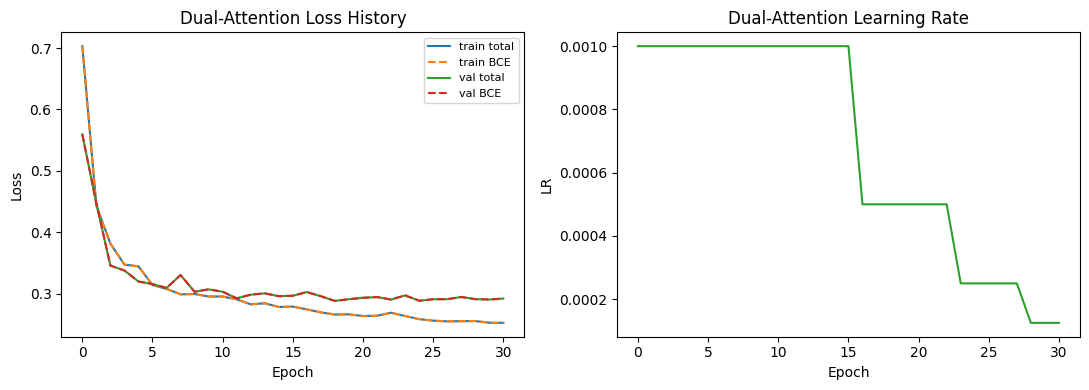

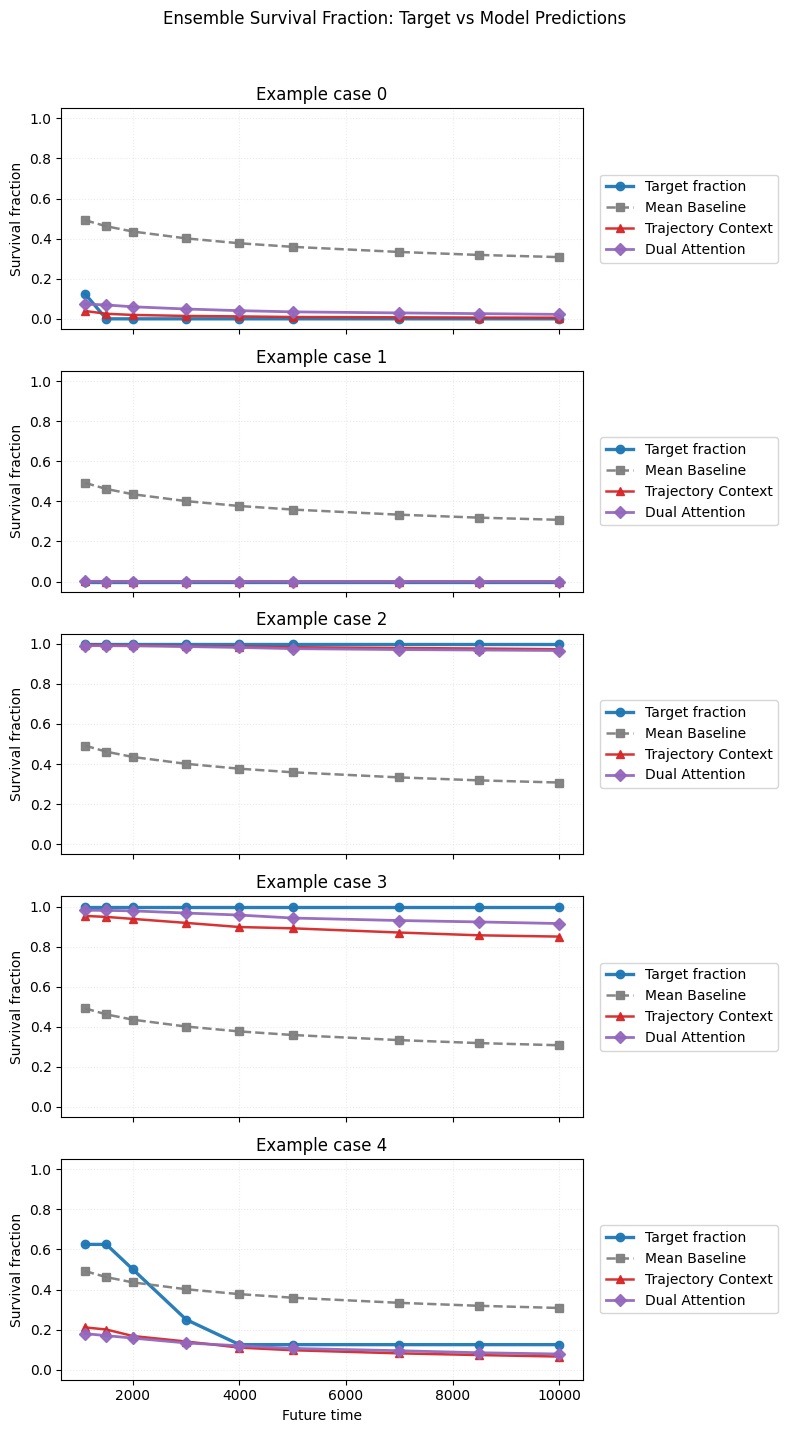

In [13]:
dual_model = DualAttentionTrajectorySurvivalModel(
    input_dim=NUM_FEATURES,
    hidden_dim=DUAL_HIDDEN_DIM,
    horizon=len(FUTURE_TIMES),
    temporal_heads=DUAL_NUM_HEADS_TEMPORAL,
    temporal_layers=DUAL_NUM_TEMPORAL_LAYERS,
    dropout=DUAL_DROPOUT,
).to(DEVICE)

dual_model, dual_history, dual_fit_info = train_trajectory_model(
    dual_model,
    train_loader=traj_train_loader,
    val_loader=traj_val_loader,
    criterion=trajectory_criterion,
    epochs=DUAL_EPOCHS,
    lr=LR,
    weight_decay=WEIGHT_DECAY,
    grad_clip_norm=GRAD_CLIP_NORM,
    scheduler_patience=SCHEDULER_PATIENCE,
    scheduler_factor=SCHEDULER_FACTOR,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
)

dual_val_metrics = evaluate_trajectory_model(dual_model, traj_val_loader, trajectory_criterion)
dual_test_metrics = evaluate_trajectory_model(dual_model, traj_test_loader, trajectory_criterion)

print("Dual-attention trajectory fit info:", dual_fit_info)
print()
print_trajectory_metrics("DUAL VAL", dual_val_metrics)
print()
print_trajectory_metrics("DUAL TEST", dual_test_metrics)
print()
print("Improvement over mean baseline on TEST ensemble_fraction_mae:", baseline_test_metrics["ensemble_fraction_mae"] - dual_test_metrics["ensemble_fraction_mae"])
print("Improvement over trajectory-context model on TEST ensemble_fraction_mae:", traj_test_metrics["ensemble_fraction_mae"] - dual_test_metrics["ensemble_fraction_mae"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(dual_history["train_loss"], label="train total")
axes[0].plot(dual_history["train_bce"], label="train BCE", linestyle="--")
axes[0].plot(dual_history["val_loss"], label="val total")
axes[0].plot(dual_history["val_bce"], label="val BCE", linestyle="--")
axes[0].set_title("Dual-Attention Loss History")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)

axes[1].plot(dual_history["lr"], color="tab:green")
axes[1].set_title("Dual-Attention Learning Rate")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("LR")

plt.tight_layout()
plt.show()

example_ids = np.arange(min(5, len(dual_test_metrics["preds"])))
fig, example_axes = plt.subplots(len(example_ids), 1, figsize=(8, 2.8 * len(example_ids)), sharex=True)
if len(example_ids) == 1:
    example_axes = [example_axes]

model_styles = [
    ("Target fraction", dual_test_metrics["targets"], "tab:blue", "o", "-", 2.4),
    ("Mean Baseline", baseline_test_metrics["preds"], "tab:gray", "s", "--", 1.8),
    ("Trajectory Context", traj_test_metrics["preds"], "tab:red", "^", "-", 1.8),
    ("Dual Attention", dual_test_metrics["preds"], "tab:purple", "D", "-", 2.0),
]
if test_metrics is not None:
    model_styles.insert(2, ("Legacy Flat", test_metrics["preds"], "tab:orange", "x", "-.", 1.8))

for ax, idx in zip(example_axes, example_ids):
    for label, values, color, marker, linestyle, linewidth in model_styles:
        ax.plot(
            FUTURE_TIMES,
            values[idx],
            label=label,
            color=color,
            marker=marker,
            linestyle=linestyle,
            linewidth=linewidth,
            markersize=6,
            alpha=0.95,
        )
    ax.set_title(f"Example case {idx}")
    ax.set_ylabel("Survival fraction")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, alpha=0.25, linestyle=":")
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=True)

example_axes[-1].set_xlabel("Future time")
fig.suptitle("Ensemble Survival Fraction: Target vs Model Predictions", y=1.02)
plt.tight_layout()
plt.show()


Comprehensive test metrics on ensemble fraction Q=mean_i p_i:
                      loss  trajectory_bce  overall_mae  overall_rmse  count_mae  final_mae  early_mae  mid_mae  late_mae  mean_bias  auc_mae  monotone_fraction
Mean baseline       0.8934          0.8934       0.3801        0.4170     3.0411     0.3540     0.4006   0.3809    0.3589     0.0000   0.3657                1.0
Trajectory context  0.3235          0.3235       0.0958        0.1682     0.7662     0.1204     0.0729   0.0968    0.1177     0.0416   0.0960                1.0
Dual attention      0.3002          0.3002       0.0845        0.1588     0.6762     0.1094     0.0619   0.0853    0.1064     0.0305   0.0835                1.0


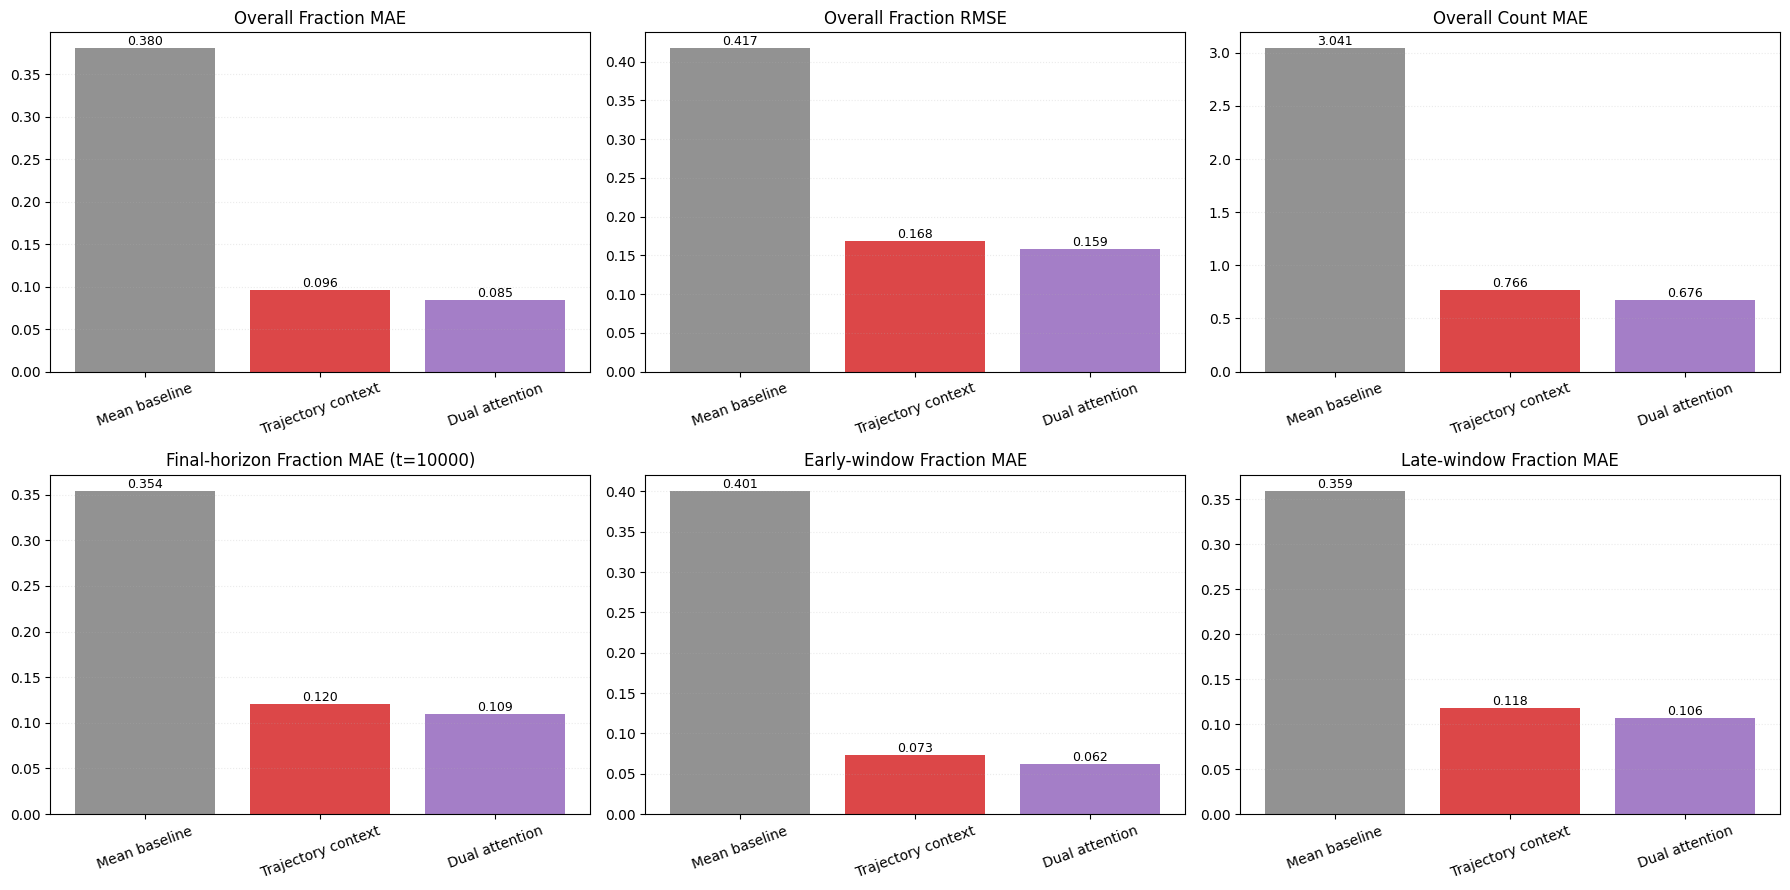

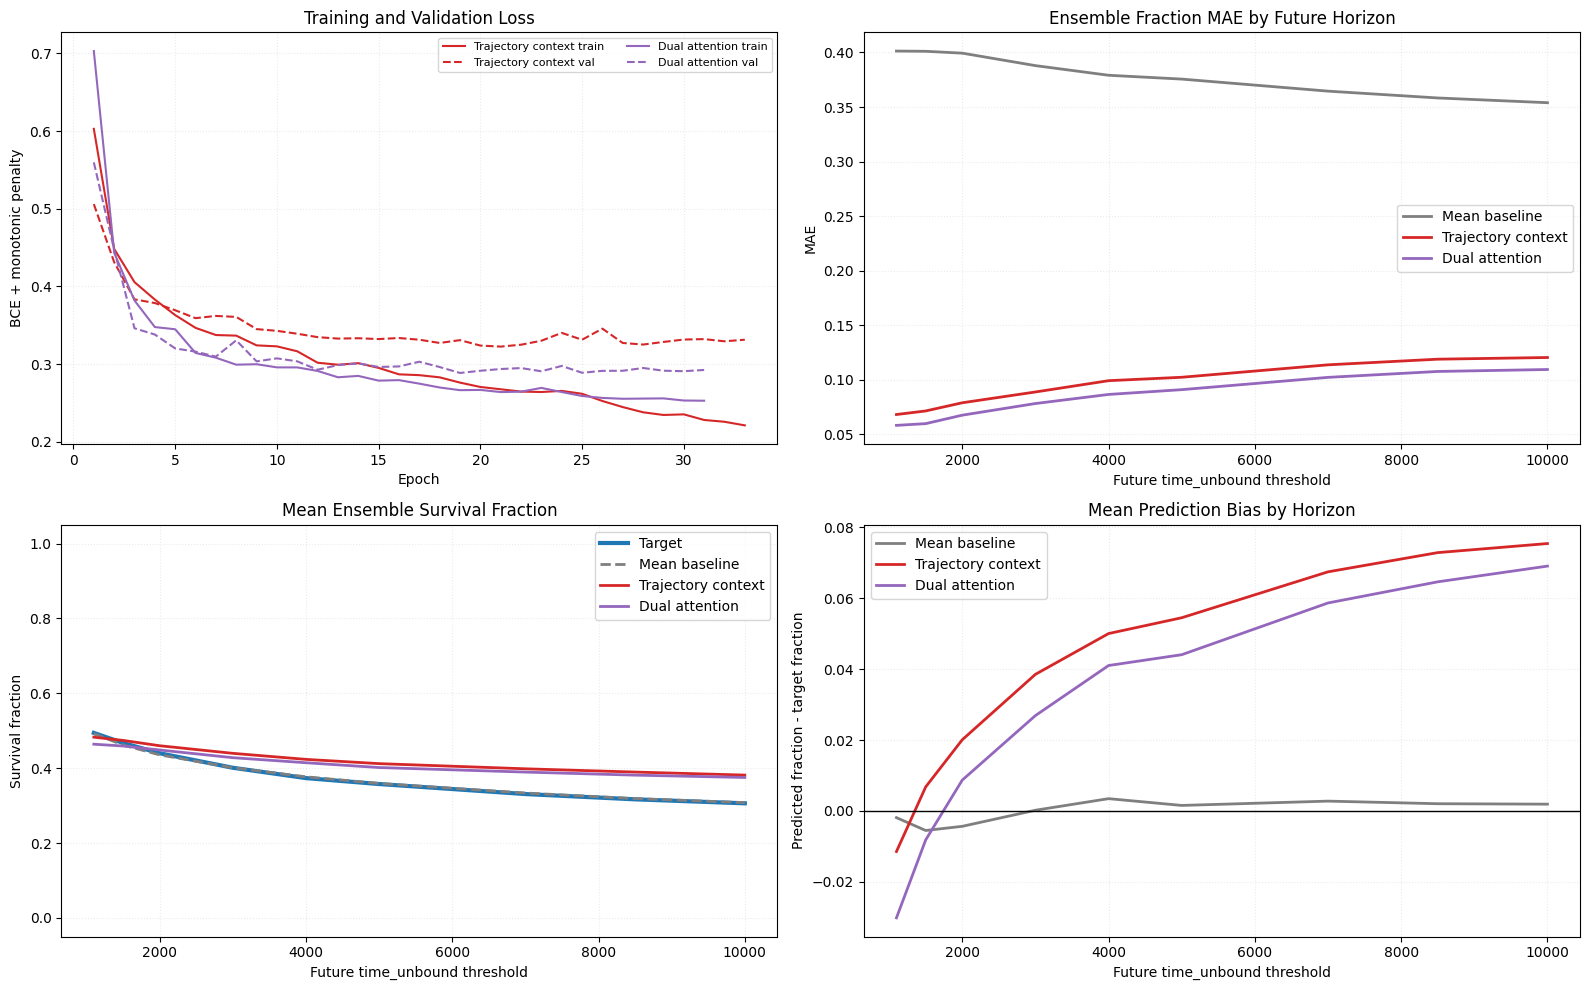

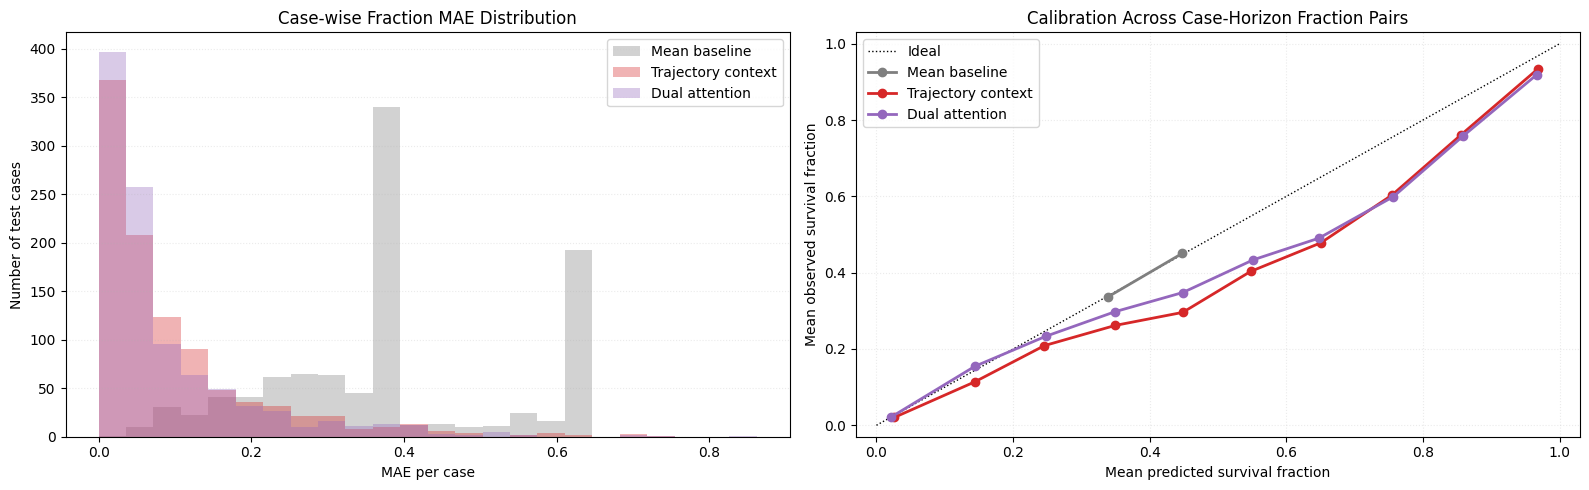

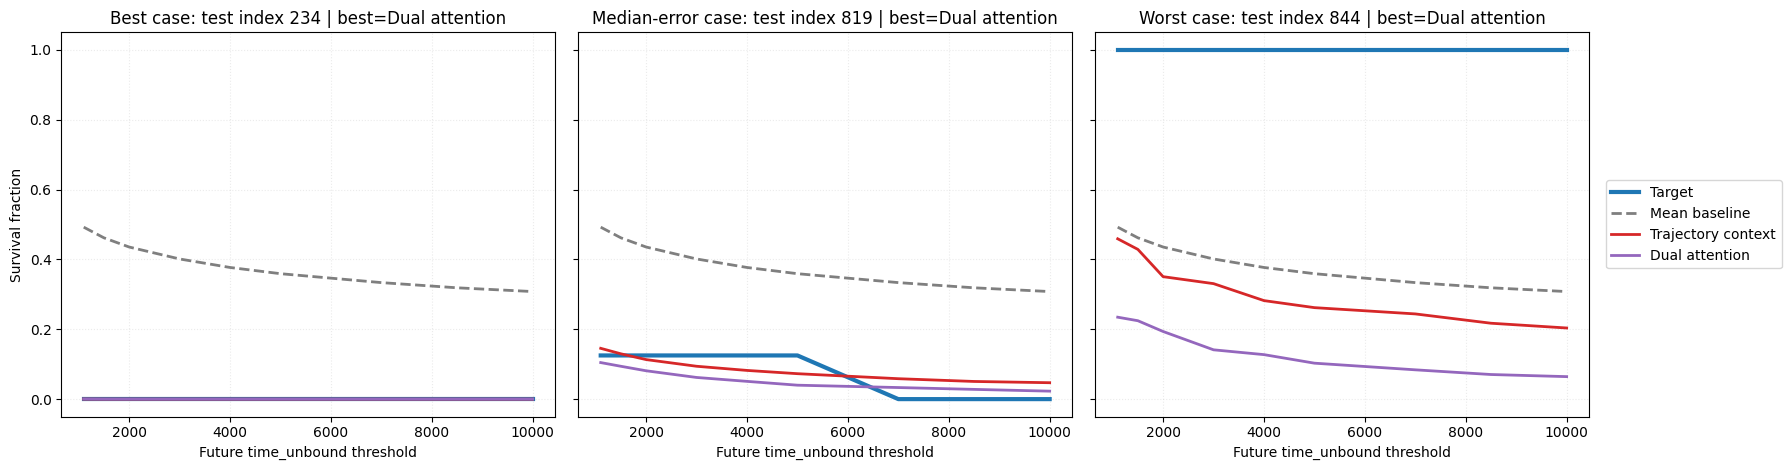

In [14]:
# Comprehensive diagnostics after all candidate models have been evaluated.
comparison_metrics = {
    "Mean baseline": baseline_test_metrics,
    "Trajectory context": traj_test_metrics,
    "Dual attention": dual_test_metrics,
}
comparison_histories = {
    "Trajectory context": traj_history,
    "Dual attention": dual_history,
}
comparison_colors = {
    "Mean baseline": "tab:gray",
    "Trajectory context": "tab:red",
    "Dual attention": "tab:purple",
}
if test_metrics is not None:
    comparison_metrics["Legacy flat"] = test_metrics
    comparison_histories["Legacy flat"] = history
    comparison_colors["Legacy flat"] = "tab:orange"


def add_curve_metrics(metrics: dict) -> dict:
    preds = metrics["preds"]
    targets = metrics["targets"]
    abs_err = np.abs(preds - targets)
    sq_err = (preds - targets) ** 2
    n_horizon = preds.shape[1]
    thirds = np.array_split(np.arange(n_horizon), 3)
    return {
        "loss": metrics["loss"],
        "trajectory_bce": metrics.get("trajectory_bce", np.nan),
        "overall_mae": float(abs_err.mean()),
        "overall_rmse": float(np.sqrt(sq_err.mean())),
        "count_mae": metrics.get("count_mae", np.nan),
        "final_mae": float(abs_err[:, -1].mean()),
        "early_mae": float(abs_err[:, thirds[0]].mean()),
        "mid_mae": float(abs_err[:, thirds[1]].mean()),
        "late_mae": float(abs_err[:, thirds[2]].mean()),
        "mean_bias": float((preds - targets).mean()),
        "auc_mae": float(np.mean(np.abs(np.trapezoid(preds, FUTURE_TIMES, axis=1) - np.trapezoid(targets, FUTURE_TIMES, axis=1))) / (FUTURE_TIMES[-1] - FUTURE_TIMES[0])),
        "monotone_fraction": metrics["monotone_fraction"],
    }


summary_df = pd.DataFrame({name: add_curve_metrics(metrics) for name, metrics in comparison_metrics.items()}).T
print("Comprehensive test metrics on ensemble fraction Q=mean_i p_i:")
print(summary_df.round(4).to_string())

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
metric_panels = [
    ("overall_mae", "Overall Fraction MAE"),
    ("overall_rmse", "Overall Fraction RMSE"),
    ("count_mae", "Overall Count MAE"),
    ("final_mae", f"Final-horizon Fraction MAE (t={int(FUTURE_TIMES[-1])})"),
    ("early_mae", "Early-window Fraction MAE"),
    ("late_mae", "Late-window Fraction MAE"),
]
for ax, (metric_name, title) in zip(axes.flat, metric_panels):
    values = summary_df[metric_name]
    colors = [comparison_colors[name] for name in values.index]
    ax.bar(values.index, values.values, color=colors, alpha=0.85)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=20)
    ax.grid(True, axis="y", alpha=0.25, linestyle=":")
    for i, value in enumerate(values.values):
        if np.isfinite(value):
            ax.text(i, value, f"{value:.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for name, hist in comparison_histories.items():
    if not hist["train_loss"]:
        continue
    epochs = np.arange(1, len(hist["train_loss"]) + 1)
    axes[0, 0].plot(epochs, hist["train_loss"], label=f"{name} train", color=comparison_colors[name], linestyle="-")
    axes[0, 0].plot(epochs, hist["val_loss"], label=f"{name} val", color=comparison_colors[name], linestyle="--")
axes[0, 0].set_title("Training and Validation Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("BCE + monotonic penalty")
axes[0, 0].grid(True, alpha=0.25, linestyle=":")
axes[0, 0].legend(fontsize=8, ncol=2)

for name, metrics in comparison_metrics.items():
    axes[0, 1].plot(FUTURE_TIMES, metrics["mae_per_horizon"], label=name, color=comparison_colors[name], linewidth=2)
axes[0, 1].set_title("Ensemble Fraction MAE by Future Horizon")
axes[0, 1].set_xlabel("Future time_unbound threshold")
axes[0, 1].set_ylabel("MAE")
axes[0, 1].grid(True, alpha=0.25, linestyle=":")
axes[0, 1].legend()

axes[1, 0].plot(FUTURE_TIMES, q_test.mean(axis=0), label="Target", color="tab:blue", linewidth=3)
for name, metrics in comparison_metrics.items():
    axes[1, 0].plot(FUTURE_TIMES, metrics["preds"].mean(axis=0), label=name, color=comparison_colors[name], linewidth=2, linestyle="--" if name == "Mean baseline" else "-")
axes[1, 0].set_title("Mean Ensemble Survival Fraction")
axes[1, 0].set_xlabel("Future time_unbound threshold")
axes[1, 0].set_ylabel("Survival fraction")
axes[1, 0].set_ylim(-0.05, 1.05)
axes[1, 0].grid(True, alpha=0.25, linestyle=":")
axes[1, 0].legend()

for name, metrics in comparison_metrics.items():
    residual = metrics["preds"] - metrics["targets"]
    axes[1, 1].plot(FUTURE_TIMES, residual.mean(axis=0), label=name, color=comparison_colors[name], linewidth=2)
axes[1, 1].axhline(0.0, color="black", linewidth=1)
axes[1, 1].set_title("Mean Prediction Bias by Horizon")
axes[1, 1].set_xlabel("Future time_unbound threshold")
axes[1, 1].set_ylabel("Predicted fraction - target fraction")
axes[1, 1].grid(True, alpha=0.25, linestyle=":")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

case_mae_by_model = {
    name: np.mean(np.abs(metrics["preds"] - metrics["targets"]), axis=1)
    for name, metrics in comparison_metrics.items()
}
max_case_mae = max(float(values.max()) for values in case_mae_by_model.values())
hist_bins = np.linspace(0.0, max(max_case_mae + 1e-6, 0.05), 25)
for name, case_mae in case_mae_by_model.items():
    axes[0].hist(case_mae, bins=hist_bins, alpha=0.35, label=name, color=comparison_colors[name])
axes[0].set_title("Case-wise Fraction MAE Distribution")
axes[0].set_xlabel("MAE per case")
axes[0].set_ylabel("Number of test cases")
axes[0].grid(True, axis="y", alpha=0.25, linestyle=":")
axes[0].legend()


def calibration_table(preds: np.ndarray, targets: np.ndarray, bins: np.ndarray) -> pd.DataFrame:
    flat_pred = preds.reshape(-1)
    flat_target = targets.reshape(-1)
    bin_ids = np.digitize(flat_pred, bins) - 1
    rows = []
    for bin_id in range(len(bins) - 1):
        mask = bin_ids == bin_id
        if mask.sum() == 0:
            continue
        rows.append({
            "bin_left": bins[bin_id],
            "bin_right": bins[bin_id + 1],
            "pred_mean": float(flat_pred[mask].mean()),
            "target_mean": float(flat_target[mask].mean()),
            "count": int(mask.sum()),
        })
    return pd.DataFrame(rows)


calibration_bins = np.linspace(0.0, 1.0, 11)
axes[1].plot([0, 1], [0, 1], color="black", linewidth=1, linestyle=":", label="Ideal")
for name, metrics in comparison_metrics.items():
    cal = calibration_table(metrics["preds"], metrics["targets"], calibration_bins)
    if not cal.empty:
        axes[1].plot(cal["pred_mean"], cal["target_mean"], marker="o", label=name, color=comparison_colors[name], linewidth=2)
axes[1].set_title("Calibration Across Case-Horizon Fraction Pairs")
axes[1].set_xlabel("Mean predicted survival fraction")
axes[1].set_ylabel("Mean observed survival fraction")
axes[1].set_xlim(-0.03, 1.03)
axes[1].set_ylim(-0.03, 1.03)
axes[1].grid(True, alpha=0.25, linestyle=":")
axes[1].legend()

plt.tight_layout()
plt.show()

best_model_name = summary_df["overall_mae"].idxmin()
best_metrics = comparison_metrics[best_model_name]
ordered_case_ids = np.argsort(np.mean(np.abs(best_metrics["preds"] - best_metrics["targets"]), axis=1))
case_ids_to_plot = [ordered_case_ids[0], ordered_case_ids[len(ordered_case_ids) // 2], ordered_case_ids[-1]]
case_titles = ["Best case", "Median-error case", "Worst case"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
for ax, case_id, title in zip(axes, case_ids_to_plot, case_titles):
    ax.plot(FUTURE_TIMES, best_metrics["targets"][case_id], label="Target", color="tab:blue", linewidth=3)
    for name, metrics in comparison_metrics.items():
        ax.plot(FUTURE_TIMES, metrics["preds"][case_id], label=name, color=comparison_colors[name], linewidth=2, linestyle="--" if name == "Mean baseline" else "-")
    ax.set_title(f"{title}: test index {case_id} | best={best_model_name}")
    ax.set_xlabel("Future time_unbound threshold")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, alpha=0.25, linestyle=":")
axes[0].set_ylabel("Survival fraction")
axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()
